****Régression linéaire : simple (1 variable) et multiple (2 variables)****

- **Cas 1 (dimension 1)** : $y = \theta_0 + \theta_1 x + \varepsilon$ avec $y = 2x + 1 + \varepsilon$
- **Cas 2 (dimension 2)** : $y = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \varepsilon$ avec $y = 2x_1 + 3x_2 + 1 + \varepsilon$

$\varepsilon$ est un bruit gaussien.

In [71]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

## PARTIE 1 : Régression simple (dimension 1)

****1) Régression avec la méthode des moindres carrés****

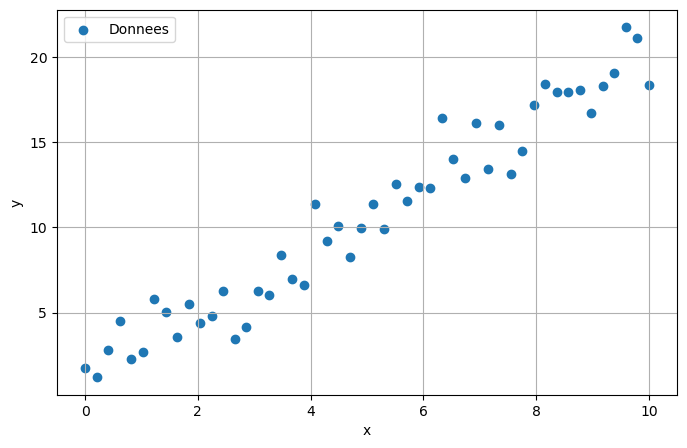

In [72]:
# 1) Jeu de donnees
np.random.seed(42)
X = np.linspace(0, 10, 50)
y = 2 * X + 1.0 + np.random.randn(50) * 1.5   # y = 2x + 1 + bruit

plt.figure(figsize=(8, 5))
plt.scatter(X, y, label="Donnees")
plt.xlabel("x"); plt.ylabel("y")
plt.legend(); plt.grid(True);
plt.show()

theta_0 = 1.097
theta_1 = 1.913


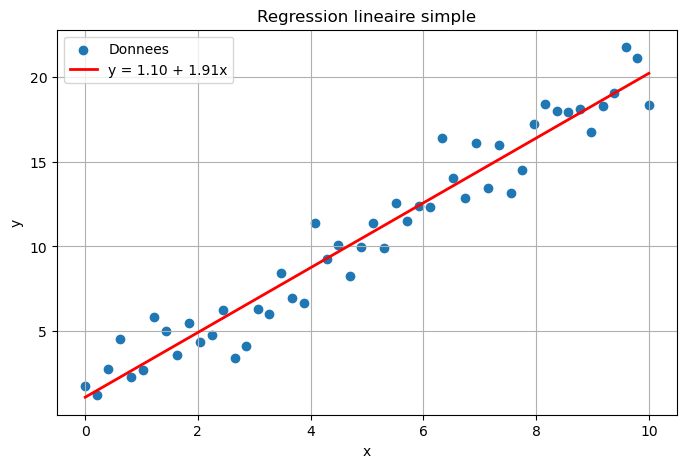

In [73]:
# 2) Calcul des paramètres par la méthode des moindres carrés
x_mean, y_mean = X.mean(), y.mean()

theta_1 = np.sum((X - x_mean) * (y - y_mean)) / np.sum((X - x_mean) ** 2)
theta_0 = y_mean - theta_1 * x_mean

print(f"theta_0 = {theta_0:.3f}")
print(f"theta_1 = {theta_1:.3f}")

# 3) Prédictions et tracé
y_pred = theta_0 + theta_1 * X

plt.figure(figsize=(8, 5))
plt.scatter(X, y, label="Donnees")
plt.plot(X, y_pred, color="red", lw=2, label=f"y = {theta_0:.2f} + {theta_1:.2f}x")
plt.xlabel("x"); plt.ylabel("y")
plt.legend(); plt.grid(True); plt.title("Regression lineaire simple")
plt.show()

In [74]:
# Coefficient de determination R^2
scr = np.sum((y - y_pred) ** 2)              # somme des carres residuels
stc = np.sum((y - y_mean) ** 2)              # somme totale des carres
R2 = 1 - scr / stc
print(f"R^2 = {R2:.4f}")

R^2 = 0.9447


****2) Régression avec la descente de gradient****

theta_0 = 1.097, theta_1 = 1.913
Cout final J = 0.9283


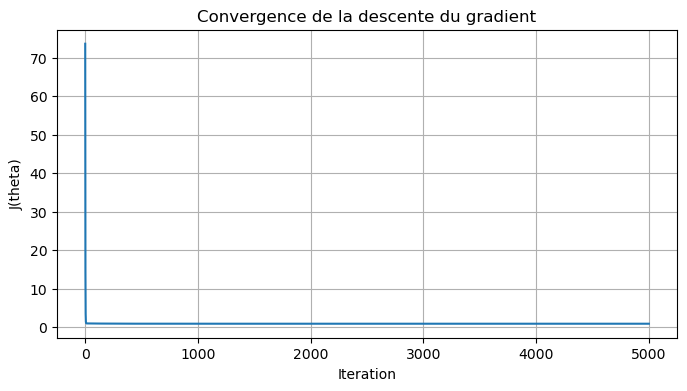

In [75]:
m = len(y)

# 3) Initialisation
theta_0, theta_1 = 0.0, 0.0
alpha = 0.01
n_iter = 5000
J_history = []

for it in range(n_iter):
    y_pred = theta_0 + theta_1 * X
    error  = y_pred - y


    # Gradients
    grad_0 = (1 / m) * np.sum(error)
    grad_1 = (1 / m) * np.sum(error * X)

    # Mise a jour
    theta_0 -= alpha * grad_0
    theta_1 -= alpha * grad_1

    # Cout
    J = (1 / (2 * m)) * np.sum(error ** 2)
    J_history.append(J)

print(f"theta_0 = {theta_0:.3f}, theta_1 = {theta_1:.3f}")
print(f"Cout final J = {J_history[-1]:.4f}")

# 4) Courbe de convergence
plt.figure(figsize=(8,4))
plt.plot(J_history)
plt.xlabel("Iteration"); plt.ylabel("J(theta)")
plt.title("Convergence de la descente du gradient")
plt.grid(True); plt.show()

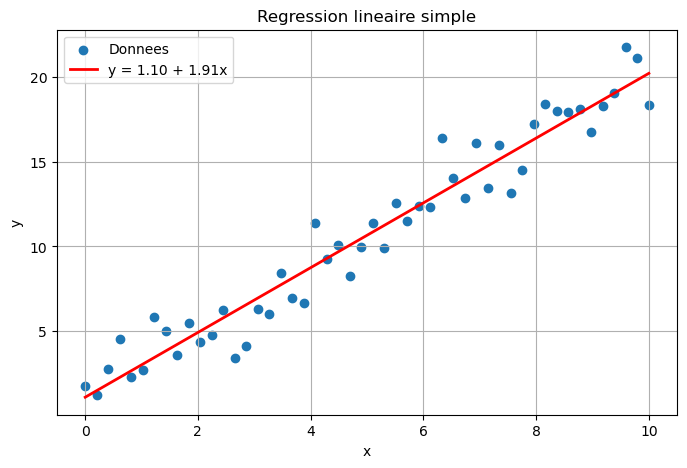

In [76]:
y_pred = theta_0 + theta_1 * X   # predictions avec les parametres finaux

plt.figure(figsize=(8, 5))
plt.scatter(X, y, label="Donnees")
plt.plot(X, y_pred, color="red", lw=2, label=f"y = {theta_0:.2f} + {theta_1:.2f}x")
plt.xlabel("x"); plt.ylabel("y")
plt.legend(); plt.grid(True); plt.title("Regression lineaire simple")
plt.show()

## PARTIE 2 : Régression multiple (dimension 2)

Modèle : $y = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \varepsilon$.

1) Régression avec la méthode des moindres carrés 

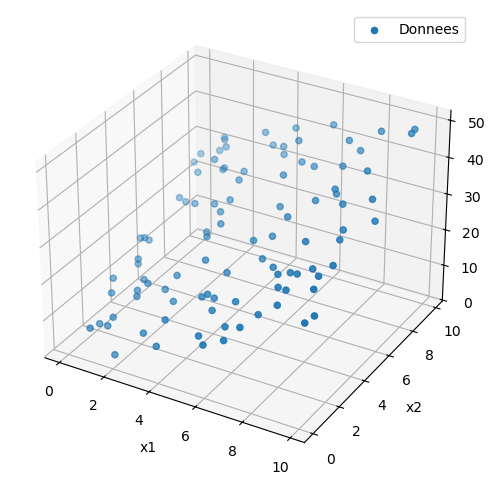

In [77]:
# 1) Jeu de donnees
np.random.seed(42)
m = 100
X1 = np.random.uniform(0, 10, m)
X2 = np.random.uniform(0, 10, m)
y = 2 * X1 + 3 * X2 + 1.0 + np.random.randn(m) * 1.5   # y = 2x1 + 3x2 + 1 + bruit

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X1, X2, y, label="Donnees")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y")
ax.legend()
plt.show()

theta_0 = 0.866
theta_1 = 1.949
theta_2 = 3.108


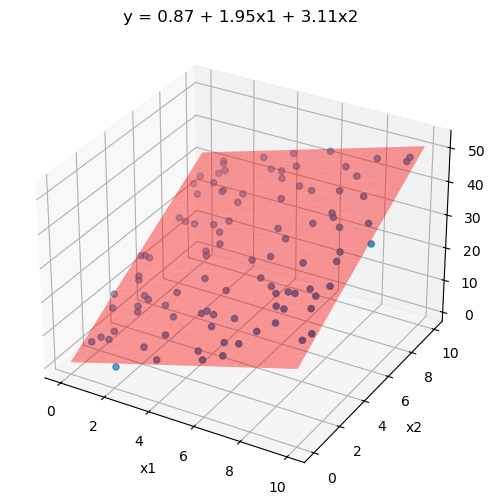

In [78]:
# 2) Calcul des param?tres par la m?thode des moindres carr?s
# Matrice de conception : colonne de 1, x1, x2
X_b = np.column_stack((np.ones(m), X1, X2))

theta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
theta_0, theta_1, theta_2 = theta

print(f"theta_0 = {theta_0:.3f}")
print(f"theta_1 = {theta_1:.3f}")
print(f"theta_2 = {theta_2:.3f}")

# 3) Pr?dictions et trac?
y_pred = X_b @ theta

x1_grille, x2_grille = np.meshgrid(
    np.linspace(0, 10, 20),
    np.linspace(0, 10, 20)
)
y_plan = theta_0 + theta_1 * x1_grille + theta_2 * x2_grille

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X1, X2, y, label="Donnees")
ax.plot_surface(x1_grille, x2_grille, y_plan, color="red", alpha=0.4)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y")
ax.set_title(f"y = {theta_0:.2f} + {theta_1:.2f}x1 + {theta_2:.2f}x2")
plt.show()

In [79]:
# Coefficient de determination R^2
y_mean = y.mean()
scr = np.sum((y - y_pred) ** 2)              # somme des carres residuels
stc = np.sum((y - y_mean) ** 2)              # somme totale des carres
R2 = 1 - scr / stc
print(f"R^2 = {R2:.4f}")

R^2 = 0.9813


****2) Régression avec la descente de gradient****

theta_0 = 0.856, theta_1 = 1.950, theta_2 = 3.109
Cout final J = 1.0639


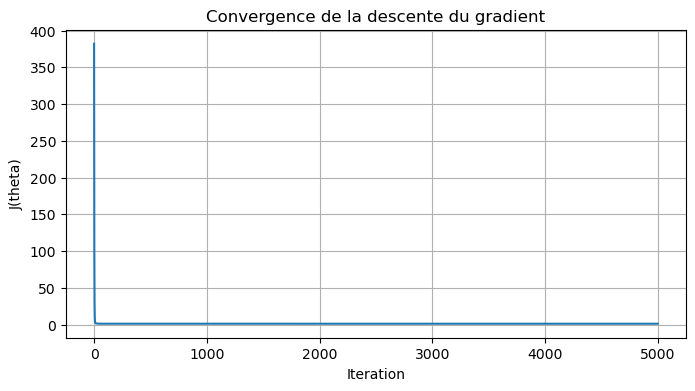

In [80]:
m = len(y)

# 3) Initialisation
theta_0, theta_1, theta_2 = 0.0, 0.0, 0.0
alpha = 0.005
n_iter = 5000
J_history = []

for it in range(n_iter):
    y_pred = theta_0 + theta_1 * X1 + theta_2 * X2
    error  = y_pred - y


    # Gradients
    grad_0 = (1 / m) * np.sum(error)
    grad_1 = (1 / m) * np.sum(error * X1)
    grad_2 = (1 / m) * np.sum(error * X2)

    # Mise a jour
    theta_0 -= alpha * grad_0
    theta_1 -= alpha * grad_1
    theta_2 -= alpha * grad_2

    # Cout
    J = (1 / (2 * m)) * np.sum(error ** 2)
    J_history.append(J)

print(f"theta_0 = {theta_0:.3f}, theta_1 = {theta_1:.3f}, theta_2 = {theta_2:.3f}")
print(f"Cout final J = {J_history[-1]:.4f}")

# 4) Courbe de convergence
plt.figure(figsize=(8,4))
plt.plot(J_history)
plt.xlabel("Iteration"); plt.ylabel("J(theta)")
plt.title("Convergence de la descente du gradient")
plt.grid(True); plt.show()

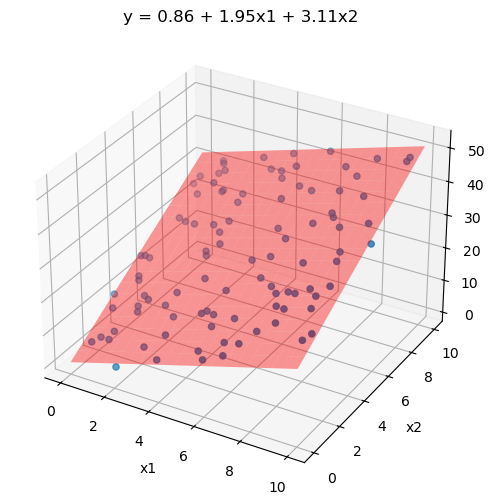

In [81]:
y_pred = theta_0 + theta_1 * X1 + theta_2 * X2   # predictions avec les parametres finaux

y_plan = theta_0 + theta_1 * x1_grille + theta_2 * x2_grille

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X1, X2, y, label="Donnees")
ax.plot_surface(x1_grille, x2_grille, y_plan, color="red", alpha=0.4)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y")
ax.set_title(f"y = {theta_0:.2f} + {theta_1:.2f}x1 + {theta_2:.2f}x2")
plt.show()

In [82]:
# Comparaison des deux methodes
theta_ls = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
theta_gd = np.array([theta_0, theta_1, theta_2])
print("Moindres carres  :", np.round(theta_ls, 3))
print("Descente gradient:", np.round(theta_gd, 3))
print("Valeurs vraies   : [1. 2. 3.]")

Moindres carres  : [0.866 1.949 3.108]
Descente gradient: [0.856 1.95  3.109]
Valeurs vraies   : [1. 2. 3.]
